# Análise da Evolução do Transporte de Passageiros no Município do Rio de Janeiro

**Disciplina:** Linguagens de Programação  
**Curso:** Sistemas de Informação  
**Período analisado:** 1995–2025  
**Fonte dos dados:** Data.Rio  

---

## 1. Introdução

A mobilidade urbana desempenha papel fundamental no funcionamento das grandes cidades, influenciando o deslocamento da população, o acesso a serviços, oportunidades de trabalho e atividades econômicas.

Este projeto analisa a evolução do movimento de passageiros em diferentes modais de transporte no Município do Rio de Janeiro entre 1995 e 2025.

A base de dados utilizada foi disponibilizada pelo Data.Rio e reúne informações sobre o transporte por ônibus, metrô, trem, bonde, transporte hidroviário e transporte aeroviário.

A análise busca identificar mudanças ao longo do tempo, diferenças entre os modais e períodos de ruptura ou recuperação no volume de passageiros.

## 2. Perguntas de Pesquisa

A análise será orientada pelas seguintes perguntas:

**RQ1 —** Como evoluiu o volume de passageiros nos diferentes modais de transporte do Município do Rio de Janeiro entre 1995 e 2025?

**RQ2 —** Quais modais ganharam ou perderam participação relativa no transporte de passageiros ao longo do período analisado?

**RQ3 —** Como períodos de forte ruptura, especialmente o ano de 2020, afetaram os diferentes modais e como ocorreu a recuperação posterior?

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [56]:
df = pd.read_parquet(
    "../data/processed/passageiros_rio.parquet"
)
df.head()

,ano,onibus,metro,trem,bonde,hidroviario,aeroviario
0,1995,1201635.707,84977.000000,98784.201000,109.042,25961.0,6623.837
1,1996,1190439.084,92515.801000,82387.692000,61.165,26828.0,6991.393
2,1997,1176041.150,70259.259000,58209.865000,146.985,26537.0,8217.142
3,1998,1183406.156,86425.601908,47786.736000,165.046,24375.0,9282.681
4,1999,1083474.892,106890.337500,64022.352528,276.432,24561.0,9415.094


In [57]:
df.shape

(31, 7)

In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ano          31 non-null     int64  
 1   onibus       31 non-null     float64
 2   metro        31 non-null     float64
 3   trem         31 non-null     float64
 4   bonde        28 non-null     float64
 5   hidroviario  31 non-null     float64
 6   aeroviario   31 non-null     float64
dtypes: float64(6), int64(1)
memory usage: 1.8 KB


In [59]:
df.isna().sum()

ano            0
onibus         0
metro          0
trem           0
bonde          3
hidroviario    0
aeroviario     0
dtype: int64

In [60]:
df.duplicated().sum()

np.int64(0)

In [61]:
df.describe()

,ano,onibus,metro,trem,bonde,hidroviario,aeroviario
count,31.000000,3.100000e+01,31.000000,31.000000,28.000000,31.000000,31.000000
mean,2010.000000,9.457898e+05,157169.903356,112975.466243,408.432107,21672.965481,16615.148516
std,9.092121,2.394668e+05,53889.987496,36719.794535,237.679927,5855.317546,7044.492420
min,1995.000000,4.542315e+05,70259.259000,47786.736000,61.165000,8564.000000,6623.837000
25%,2002.500000,7.923943e+05,113201.802750,86987.233500,224.642500,19708.500000,10591.498500
50%,2010.000000,9.312992e+05,152746.976000,98784.201000,360.966500,22103.000000,14464.058000
75%,2017.500000,1.179724e+06,188281.017500,142942.113500,587.704250,26533.367437,23988.698000
max,2025.000000,1.326079e+06,253613.926000,181010.488000,952.860000,29206.477000,27413.965000


In [62]:
colunas_modais = [
    "onibus",
    "metro",
    "trem",
    "bonde",
    "hidroviario",
    "aeroviario"
]

for modal in colunas_modais:
    ano_max = df.loc[df[modal].idxmax(), "ano"]
    valor_max = df[modal].max()

    ano_min = df.loc[df[modal].idxmin(), "ano"]
    valor_min = df[modal].min()

    print(f"{modal.upper()}")
    print(f"Maior valor: {valor_max:.2f} em {ano_max}")
    print(f"Menor valor: {valor_min:.2f} em {ano_min}")
    print("-" * 40)

ONIBUS
Maior valor: 1326078.95 em 2015
Menor valor: 454231.51 em 2021
----------------------------------------
METRO
Maior valor: 253613.93 em 2016
Menor valor: 70259.26 em 1997
----------------------------------------
TREM
Maior valor: 181010.49 em 2016
Menor valor: 47786.74 em 1998
----------------------------------------
BONDE
Maior valor: 952.86 em 2004
Menor valor: 61.16 em 1996
----------------------------------------
HIDROVIARIO
Maior valor: 29206.48 em 2011
Menor valor: 8564.00 em 2020
----------------------------------------
AEROVIARIO
Maior valor: 27413.97 em 2014
Menor valor: 6623.84 em 1995
----------------------------------------


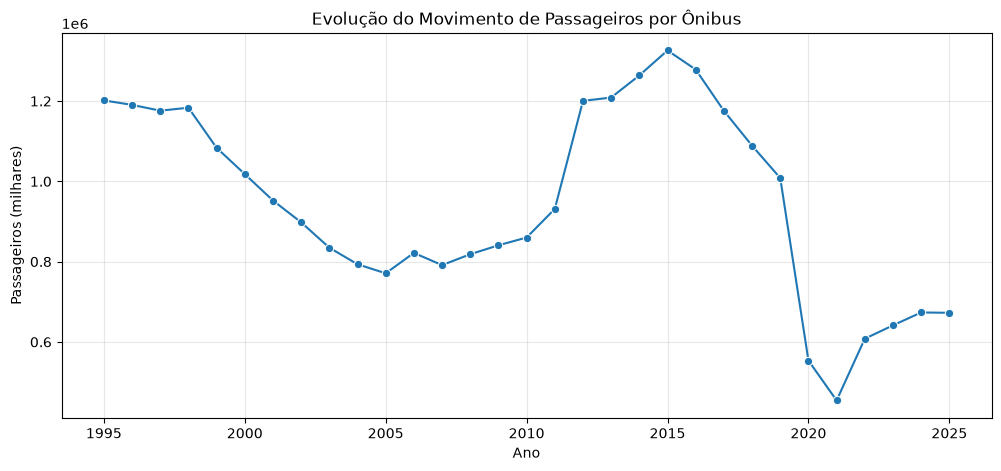

In [63]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=df,
    x="ano",
    y="onibus",
    marker="o"
)

plt.title("Evolução do Movimento de Passageiros por Ônibus")
plt.xlabel("Ano")
plt.ylabel("Passageiros (milhares)")
plt.grid(True, alpha=0.3)

plt.savefig(
    "../docs/assets/evolucao_onibus.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [64]:
df_modais = df.melt(
    id_vars="ano",
    value_vars=[
        "metro",
        "trem",
        "bonde",
        "hidroviario",
        "aeroviario"
    ],
    var_name="modal",
    value_name="passageiros"
)

df_modais.head()

,ano,modal,passageiros
0,1995,metro,84977.000000
1,1996,metro,92515.801000
2,1997,metro,70259.259000
3,1998,metro,86425.601908
4,1999,metro,106890.337500


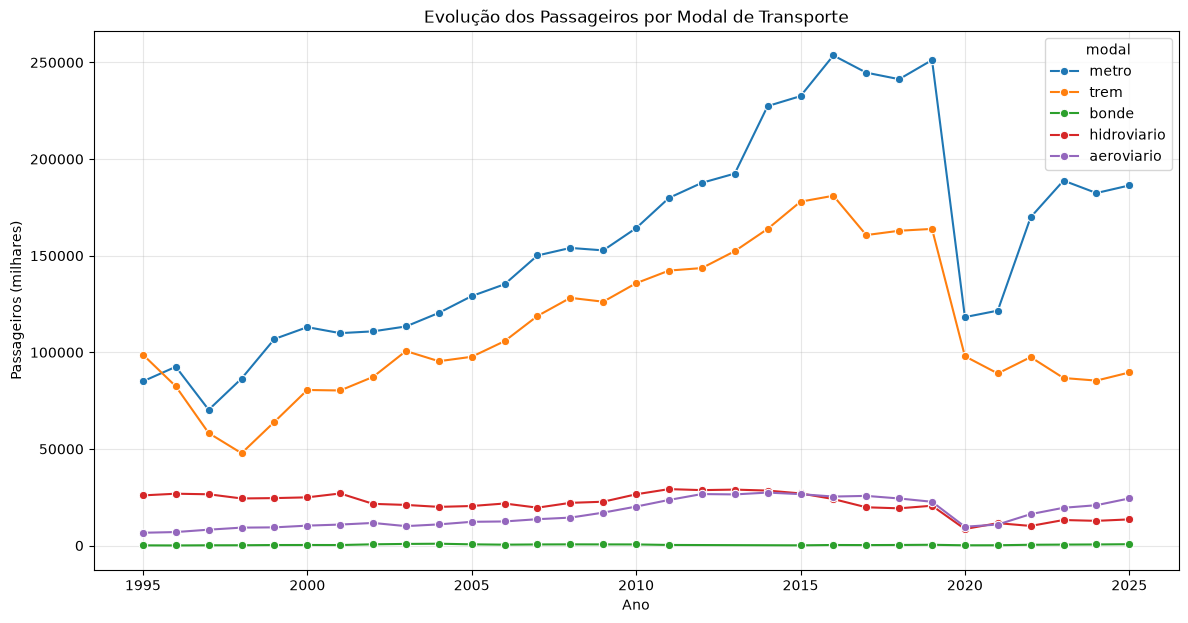

In [65]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=df_modais,
    x="ano",
    y="passageiros",
    hue="modal",
    marker="o"
)

plt.title("Evolução dos Passageiros por Modal de Transporte")
plt.xlabel("Ano")
plt.ylabel("Passageiros (milhares)")
plt.grid(True, alpha=0.3)

plt.savefig(
    "../docs/assets/evolucao_modais.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretação inicial

A análise temporal evidencia comportamentos distintos entre os modais de transporte ao longo do período de 1995 a 2025.

O transporte por ônibus apresenta o maior volume absoluto de passageiros em praticamente todo o período analisado. Após uma redução entre o final da década de 1990 e meados dos anos 2000, observa-se uma recuperação significativa, atingindo seu maior valor em 2015. A partir desse período ocorre uma nova tendência de queda, intensificada nos anos de 2020 e 2021, seguida por recuperação parcial nos anos posteriores.

Metrô e trem apresentam crescimento relevante principalmente entre os anos 2000 e meados da década de 2010. Ambos sofrem forte redução em 2020, mas apresentam padrões distintos de recuperação nos anos seguintes.

Os transportes hidroviário e aeroviário possuem volumes menores quando comparados aos principais modais terrestres. O bonde apresenta valores ainda mais baixos, fazendo com que sua trajetória seja pouco visível quando representada na mesma escala dos demais modais.

Esses resultados indicam que a comparação apenas por valores absolutos não é suficiente para compreender completamente a evolução relativa dos diferentes meios de transporte.

In [66]:
df_indice = df.copy()

for modal in colunas_modais:
    valor_base = df_indice.loc[
        df_indice["ano"] == 1995,
        modal
    ].iloc[0]

    df_indice[modal] = (
        df_indice[modal] / valor_base
    ) * 100

In [67]:
df_indice_longo = df_indice.melt(
    id_vars="ano",
    value_vars=colunas_modais,
    var_name="modal",
    value_name="indice"
)

df_indice_longo.head()

,ano,modal,indice
0,1995,onibus,100.000000
1,1996,onibus,99.068218
2,1997,onibus,97.870024
3,1998,onibus,98.482939
4,1999,onibus,90.166669


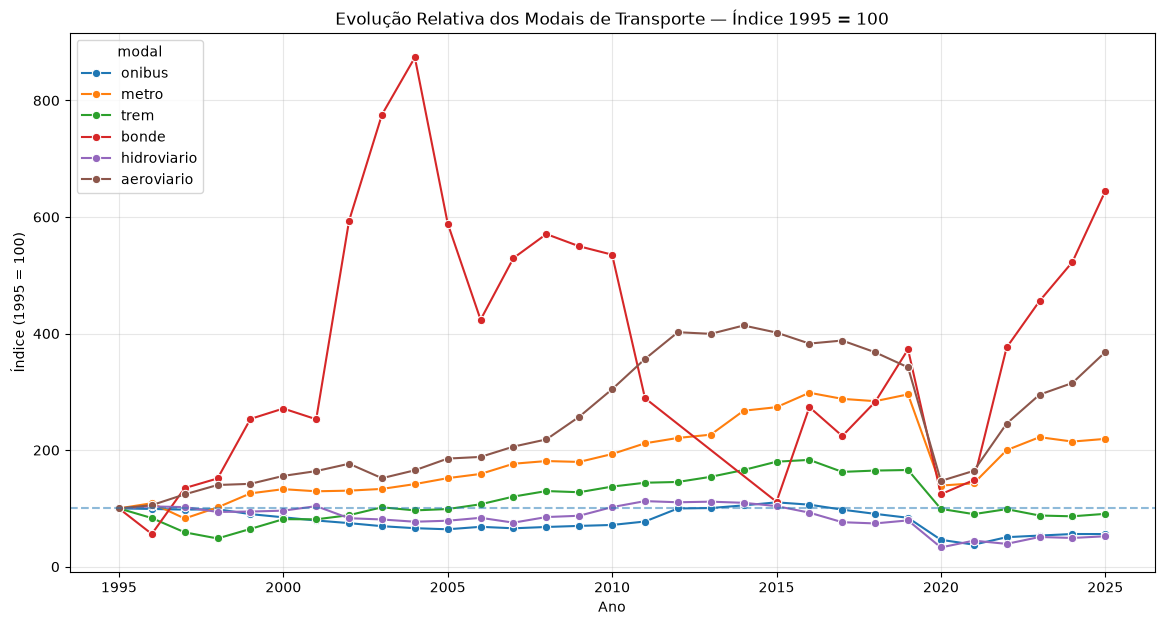

In [68]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=df_indice_longo,
    x="ano",
    y="indice",
    hue="modal",
    marker="o"
)

plt.axhline(
    y=100,
    linestyle="--",
    alpha=0.5
)

plt.title("Evolução Relativa dos Modais de Transporte — Índice 1995 = 100")
plt.xlabel("Ano")
plt.ylabel("Índice (1995 = 100)")
plt.grid(True, alpha=0.3)

plt.savefig(
    "../docs/assets/indice_1995.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretação da evolução relativa

A normalização dos dados pelo índice 1995 = 100 permite comparar a evolução proporcional dos modais independentemente das diferenças de escala entre seus volumes absolutos.

O bonde apresenta as maiores variações relativas, resultado relacionado ao baixo volume registrado no início da série. Dessa forma, aumentos absolutos relativamente pequenos produzem grandes variações percentuais quando comparados ao valor-base de 1995.

O metrô e o transporte aeroviário também apresentam crescimento expressivo em relação aos níveis iniciais, especialmente ao longo das décadas de 2000 e 2010.

Por outro lado, o transporte por ônibus apresenta períodos prolongados abaixo do nível observado em 1995, apesar de permanecer como o modal de maior volume absoluto de passageiros.

Também é possível observar uma ruptura generalizada em torno de 2020, seguida por diferentes níveis de recuperação entre os modais nos anos posteriores.

A análise conjunta dos valores absolutos e relativos demonstra que crescimento proporcional e volume total representam dimensões distintas do comportamento dos sistemas de transporte.

In [69]:
modais_participacao = [
    "onibus",
    "metro",
    "trem",
    "hidroviario",
    "aeroviario"
]

df_participacao = df[
    ["ano"] + modais_participacao
].copy()

In [70]:
df_participacao["total_passageiros"] = (
    df_participacao[modais_participacao]
    .sum(axis=1)
)

In [71]:
df_participacao.head()

,ano,onibus,metro,trem,hidroviario,aeroviario,total_passageiros
0,1995,1201635.707,84977.000000,98784.201000,25961.0,6623.837,1.417982e+06
1,1996,1190439.084,92515.801000,82387.692000,26828.0,6991.393,1.399162e+06
2,1997,1176041.150,70259.259000,58209.865000,26537.0,8217.142,1.339264e+06
3,1998,1183406.156,86425.601908,47786.736000,24375.0,9282.681,1.351276e+06
4,1999,1083474.892,106890.337500,64022.352528,24561.0,9415.094,1.288364e+06


In [72]:
for modal in modais_participacao:

    df_participacao[f"participacao_{modal}"] = (
        df_participacao[modal]
        / df_participacao["total_passageiros"]
    ) * 100

In [73]:
colunas_participacao = [
    f"participacao_{modal}"
    for modal in modais_participacao
]

df_participacao[
    ["ano"] + colunas_participacao
].head()

,ano,participacao_onibus,participacao_metro,participacao_trem,participacao_hidroviario,participacao_aeroviario
0,1995,84.742678,5.992813,6.966535,1.830842,0.467131
1,1996,85.082293,6.612230,5.888360,1.917433,0.499684
2,1997,87.812469,5.246108,4.346406,1.981461,0.613556
3,1998,87.576927,6.395850,3.536415,1.803850,0.686957
4,1999,84.096976,8.296597,4.969276,1.906372,0.730779


In [74]:
df_participacao["soma_participacoes"] = (
    df_participacao[colunas_participacao]
    .sum(axis=1)
)

df_participacao[
    ["ano", "soma_participacoes"]
].head()

,ano,soma_participacoes
0,1995,100.0
1,1996,100.0
2,1997,100.0
3,1998,100.0
4,1999,100.0


In [75]:
df_participacao_longo = df_participacao.melt(
    id_vars="ano",
    value_vars=colunas_participacao,
    var_name="modal",
    value_name="participacao"
)

In [76]:
df_participacao_longo["modal"] = (
    df_participacao_longo["modal"]
    .str.replace("participacao_", "")
)

In [77]:
df_participacao_longo.head()

,ano,modal,participacao
0,1995,onibus,84.742678
1,1996,onibus,85.082293
2,1997,onibus,87.812469
3,1998,onibus,87.576927
4,1999,onibus,84.096976


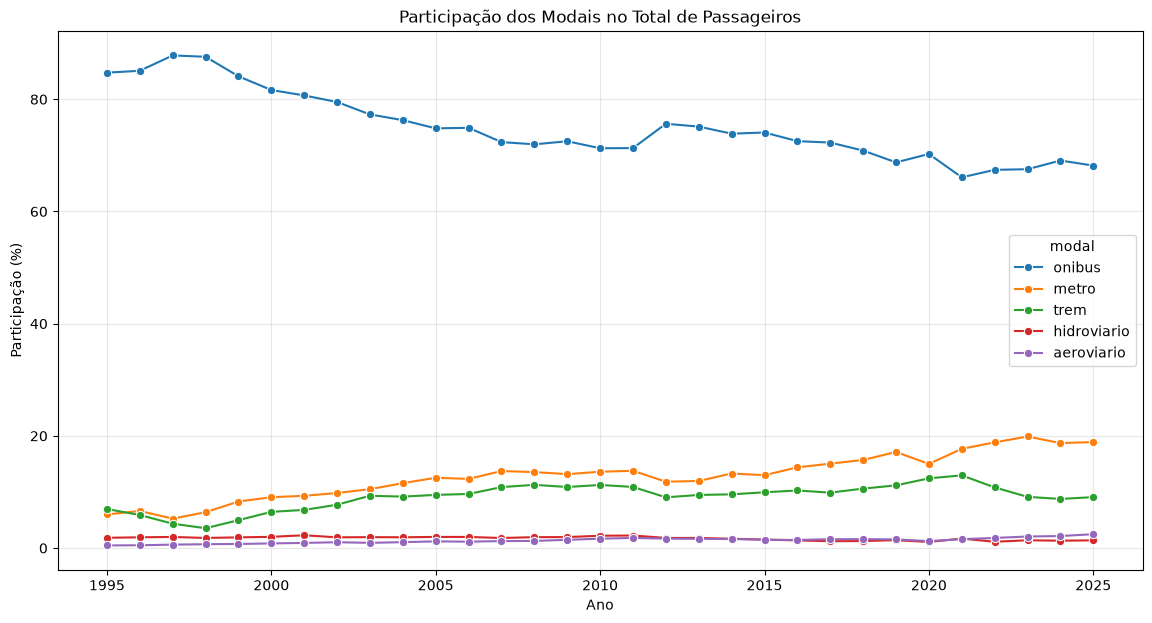

In [78]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=df_participacao_longo,
    x="ano",
    y="participacao",
    hue="modal",
    marker="o"
)

plt.title(
    "Participação dos Modais no Total de Passageiros"
)
plt.xlabel("Ano")
plt.ylabel("Participação (%)")
plt.grid(True, alpha=0.3)

plt.savefig(
    "../docs/assets/participacao_modais.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretação da participação dos modais

A análise da participação relativa dos modais mostra que o transporte por ônibus permaneceu como o principal meio de deslocamento entre os modais analisados durante todo o período. Entretanto, sua participação no total apresentou redução gradual ao longo das três décadas.

No início da série, o ônibus concentrava mais de 80% dos passageiros considerados na análise. Ao longo do tempo, essa participação diminuiu, chegando a valores próximos de 70% nos anos mais recentes.

Em sentido contrário, o metrô apresentou crescimento significativo de participação, aumentando sua presença relativa no sistema de transporte ao longo do período analisado. O trem também apresentou crescimento em diferentes momentos da série, embora com redução de participação nos anos mais recentes.

Os transportes hidroviário e aeroviário mantiveram participações menores quando comparados aos principais modais terrestres.

Esses resultados indicam uma mudança gradual na composição do transporte de passageiros, com redução da concentração no transporte por ônibus e aumento da importância relativa de outros modais, especialmente o metrô.

In [79]:
variacao_2020 = []

for modal in colunas_modais:

    valor_2019 = df.loc[
        df["ano"] == 2019,
        modal
    ].iloc[0]

    valor_2020 = df.loc[
        df["ano"] == 2020,
        modal
    ].iloc[0]

    variacao_percentual = (
        (valor_2020 - valor_2019)
        / valor_2019
    ) * 100

    variacao_2020.append({
        "modal": modal,
        "valor_2019": valor_2019,
        "valor_2020": valor_2020,
        "variacao_percentual": variacao_percentual
    })

df_variacao_2020 = pd.DataFrame(variacao_2020)

df_variacao_2020

,modal,valor_2019,valor_2020,variacao_percentual
0,onibus,1.008326e+06,553590.529,-45.098073
1,metro,2.512332e+05,118206.562,-52.949465
2,trem,1.638554e+05,97959.000,-40.216187
3,bonde,4.066320e+02,135.536,-66.668634
4,hidroviario,2.060900e+04,8564.000,-58.445339
5,aeroviario,2.265562e+04,9744.513,-56.988549


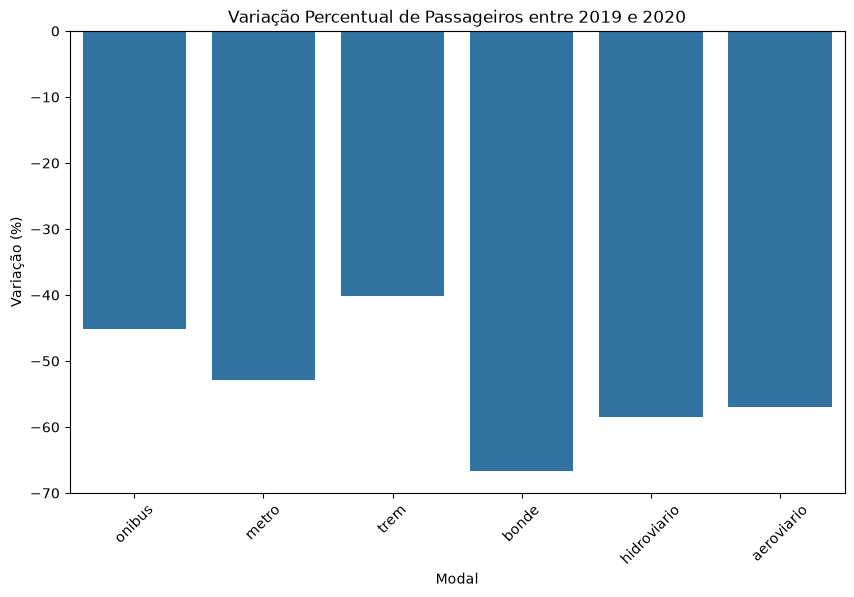

In [80]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_variacao_2020,
    x="modal",
    y="variacao_percentual"
)

plt.axhline(
    y=0,
    linestyle="--",
    alpha=0.5
)

plt.title("Variação Percentual de Passageiros entre 2019 e 2020")
plt.xlabel("Modal")
plt.ylabel("Variação (%)")
plt.xticks(rotation=45)

plt.savefig(
    "../docs/assets/variacao_2019_2020.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [81]:
recuperacao_2025 = []

for modal in colunas_modais:

    valor_2019 = df.loc[
        df["ano"] == 2019,
        modal
    ].iloc[0]

    valor_2025 = df.loc[
        df["ano"] == 2025,
        modal
    ].iloc[0]

    indice_recuperacao = (
        valor_2025 / valor_2019
    ) * 100

    recuperacao_2025.append({
        "modal": modal,
        "valor_2019": valor_2019,
        "valor_2025": valor_2025,
        "indice_recuperacao": indice_recuperacao
    })

df_recuperacao_2025 = pd.DataFrame(
    recuperacao_2025
)

df_recuperacao_2025

,modal,valor_2019,valor_2025,indice_recuperacao
0,onibus,1.008326e+06,672555.854,66.700224
1,metro,2.512332e+05,186352.018,74.174919
2,trem,1.638554e+05,89559.000,54.657341
3,bonde,4.066320e+02,702.768,172.826536
4,hidroviario,2.060900e+04,13542.428,65.711233
5,aeroviario,2.265562e+04,24391.798,107.663320


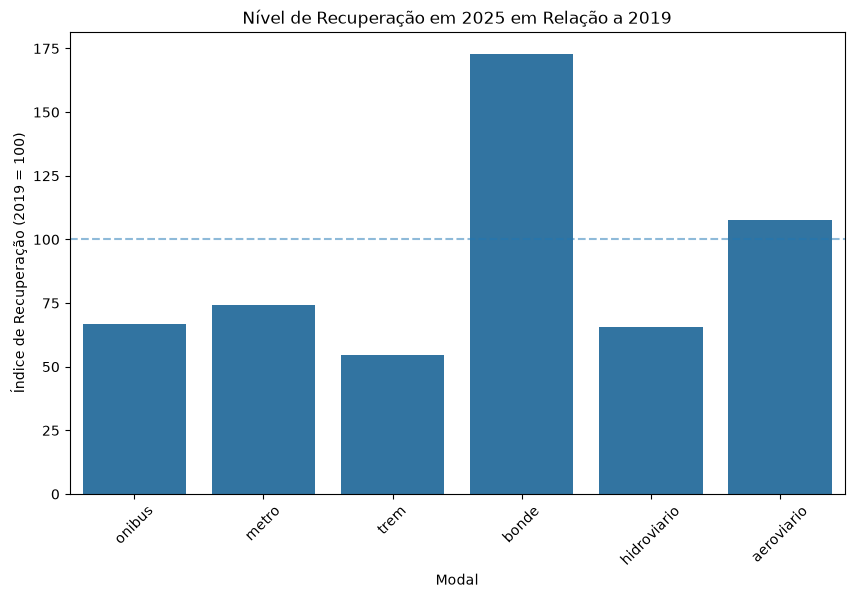

In [82]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_recuperacao_2025,
    x="modal",
    y="indice_recuperacao"
)

plt.axhline(
    y=100,
    linestyle="--",
    alpha=0.5
)

plt.title("Nível de Recuperação em 2025 em Relação a 2019")
plt.xlabel("Modal")
plt.ylabel("Índice de Recuperação (2019 = 100)")
plt.xticks(rotation=45)

plt.savefig(
    "../docs/assets/recuperacao_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Impacto da ruptura de 2020 e recuperação posterior

A comparação entre 2019 e 2020 evidencia uma redução no número de passageiros em todos os modais analisados, caracterizando uma ruptura significativa nas séries históricas.

O bonde apresentou a maior redução proporcional, com queda de aproximadamente 66,7%, seguido pelo transporte hidroviário e aeroviário, ambos com reduções superiores a 50%. O metrô também apresentou queda expressiva, enquanto ônibus e trem registraram reduções relativamente menores, embora ainda significativas.

A análise da recuperação em 2025 mostra comportamentos distintos entre os modais. O transporte aeroviário superou o volume registrado em 2019, atingindo aproximadamente 107,7% do nível anterior à ruptura.

O bonde também apresentou valor superior ao registrado em 2019, alcançando aproximadamente 172,8%. Entretanto, esse resultado deve ser interpretado com cautela, pois o modal opera em uma escala absoluta muito menor, fazendo com que pequenas variações no número de passageiros produzam grandes mudanças percentuais.

Por outro lado, ônibus, metrô, trem e transporte hidroviário ainda não retornaram aos níveis observados em 2019. Entre esses modais, o trem apresenta a menor recuperação relativa em 2025, correspondendo a aproximadamente 54,7% do volume registrado em 2019.

Os resultados indicam que a ruptura observada em 2020 afetou todos os modais, mas a intensidade da queda e o ritmo de recuperação foram diferentes entre eles.

In [83]:
correlacao = df[colunas_modais].corr()

correlacao

,onibus,metro,trem,bonde,hidroviario,aeroviario
onibus,1.000000,0.211814,0.384696,-0.473106,0.807978,0.269102
metro,0.211814,1.000000,0.859180,0.057564,-0.036961,0.928057
trem,0.384696,0.859180,1.000000,-0.001234,0.260457,0.805151
bonde,-0.473106,0.057564,-0.001234,1.000000,-0.210143,0.093167
hidroviario,0.807978,-0.036961,0.260457,-0.210143,1.000000,0.115346
aeroviario,0.269102,0.928057,0.805151,0.093167,0.115346,1.000000


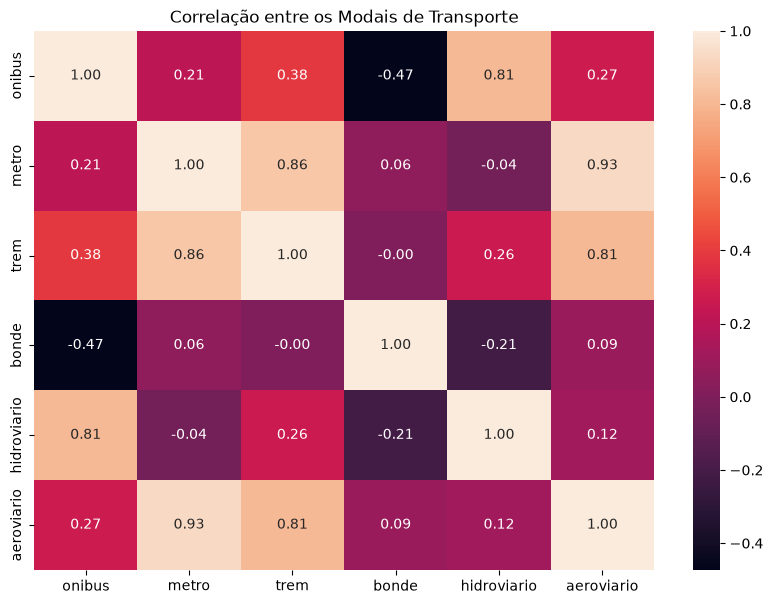

In [84]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlacao,
    annot=True,
    fmt=".2f"
)

plt.title("Correlação entre os Modais de Transporte")

plt.savefig(
    "../docs/assets/correlacao_modais.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretação da correlação entre os modais

A matriz de correlação indica que alguns modais apresentaram trajetórias historicamente semelhantes ao longo do período analisado.

A correlação mais elevada foi observada entre metrô e transporte aeroviário, com valor aproximado de 0,93, indicando forte associação positiva entre suas séries temporais. Também foram observadas correlações elevadas entre metrô e trem (0,86), trem e transporte aeroviário (0,81) e ônibus e transporte hidroviário (0,81).

Por outro lado, algumas combinações apresentaram correlação próxima de zero, como metrô e transporte hidroviário, indicando pouca associação linear entre suas trajetórias.

O bonde apresentou comportamento distinto dos demais modais, incluindo correlação negativa moderada com o transporte por ônibus, de aproximadamente -0,47.

Esses resultados devem ser interpretados como associações estatísticas entre as séries e não como relações de causa e efeito. Além disso, eventos comuns que afetam simultaneamente diversos modais, como a forte ruptura observada em 2020, podem influenciar os valores de correlação.

In [85]:
estatisticas_modais = pd.DataFrame({
    "media": df[colunas_modais].mean(),
    "desvio_padrao": df[colunas_modais].std()
})

estatisticas_modais["coeficiente_variacao"] = (
    estatisticas_modais["desvio_padrao"]
    / estatisticas_modais["media"]
) * 100

estatisticas_modais

,media,desvio_padrao,coeficiente_variacao
onibus,945789.756679,239466.838733,25.319246
metro,157169.903356,53889.987496,34.287727
trem,112975.466243,36719.794535,32.502450
bonde,408.432107,237.679927,58.193252
hidroviario,21672.965481,5855.317546,27.016688
aeroviario,16615.148516,7044.492420,42.398011


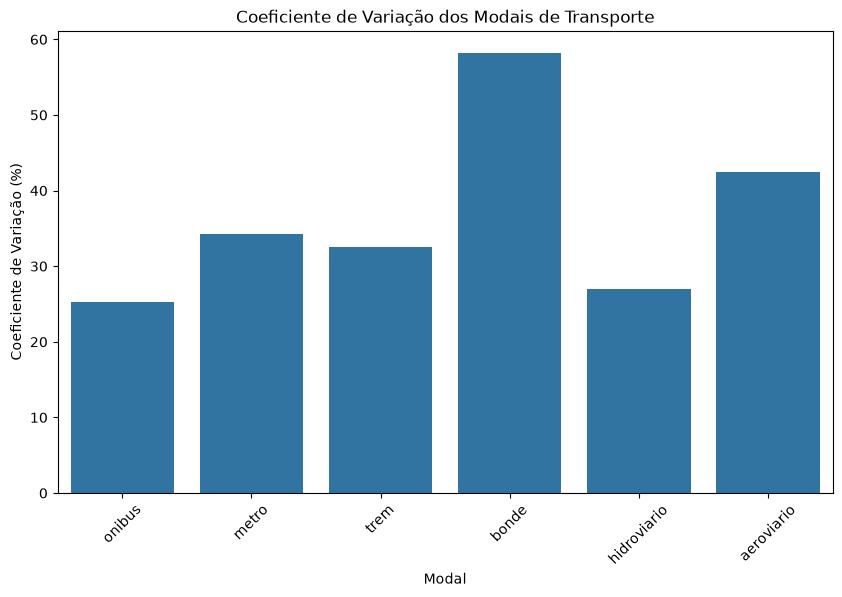

In [86]:
estatisticas_plot = (
    estatisticas_modais
    .reset_index()
    .rename(columns={"index": "modal"})
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=estatisticas_plot,
    x="modal",
    y="coeficiente_variacao"
)

plt.title("Coeficiente de Variação dos Modais de Transporte")
plt.xlabel("Modal")
plt.ylabel("Coeficiente de Variação (%)")
plt.xticks(rotation=45)

plt.savefig(
    "../docs/assets/coeficiente_variacao.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretação da variabilidade dos modais

O coeficiente de variação permite comparar a dispersão relativa das séries, independentemente das diferenças de escala entre os modais.

O transporte por ônibus apresentou o menor coeficiente de variação, de aproximadamente 25,3%, indicando maior estabilidade relativa ao longo do período analisado.

O transporte hidroviário também apresentou dispersão relativamente baixa, com aproximadamente 27,0%. Trem e metrô apresentaram níveis intermediários de variabilidade, com cerca de 32,5% e 34,3%, respectivamente.

O transporte aeroviário apresentou maior oscilação, com coeficiente de variação próximo de 42,4%.

O bonde apresentou o maior coeficiente de variação, aproximadamente 58,2%, indicando forte oscilação relativa em relação à sua média histórica. Esse resultado deve ser interpretado juntamente com o baixo volume absoluto desse modal e com os valores ausentes existentes em parte da série.

Assim, os resultados demonstram que estabilidade relativa e volume de passageiros representam dimensões distintas da análise.

## 8. Síntese dos Principais Resultados

A análise dos dados de transporte de passageiros no Município do Rio de Janeiro entre 1995 e 2025 revelou mudanças relevantes na evolução e na composição dos diferentes modais.

Em termos absolutos, o transporte por ônibus permaneceu como o principal modal durante todo o período analisado. Entretanto, sua participação relativa no conjunto dos transportes apresentou redução ao longo das décadas.

O metrô apresentou crescimento importante tanto em volume quanto em participação relativa, especialmente a partir dos anos 2000. O trem também apresentou crescimento em determinados períodos, embora sua recuperação após 2020 tenha sido mais limitada.

A análise dos índices relativos mostrou que modais de menor escala, como o bonde, podem apresentar grandes variações percentuais sem necessariamente representar elevados volumes absolutos.

A ruptura observada entre 2019 e 2020 afetou todos os modais, com reduções significativas no número de passageiros. A recuperação posterior ocorreu de maneira desigual: em 2025, alguns modais já haviam superado os níveis de 2019, enquanto outros ainda permaneciam abaixo desse patamar.

A matriz de correlação revelou fortes associações positivas entre algumas séries, especialmente entre metrô e transporte aeroviário, metrô e trem e ônibus e transporte hidroviário. Entretanto, essas associações não devem ser interpretadas como relações de causalidade.

Por fim, o coeficiente de variação mostrou que ônibus e transporte hidroviário apresentaram maior estabilidade relativa, enquanto bonde e transporte aeroviário registraram maior volatilidade ao longo da série histórica.

## 9. Conclusão

O estudo permitiu analisar a evolução histórica dos principais modais de transporte de passageiros no Município do Rio de Janeiro entre 1995 e 2025.

Os resultados demonstram que o sistema de transporte passou por mudanças significativas ao longo das três décadas analisadas. Embora o transporte por ônibus permaneça dominante em termos absolutos, sua participação relativa apresentou redução, enquanto o metrô ampliou sua importância ao longo do período.

A análise também evidenciou a forte ruptura observada em 2020, seguida por padrões distintos de recuperação entre os modais. Em 2025, nem todos os meios de transporte haviam retornado aos níveis observados antes dessa ruptura.

As análises de correlação e dispersão complementaram a avaliação temporal, permitindo identificar semelhanças entre algumas séries e diferenças no grau de estabilidade dos modais.

Como limitações, destaca-se a existência de valores ausentes na série do bonde e o fato de a base apresentar dados agregados anuais, o que restringe análises mais detalhadas sobre sazonalidade, localização ou perfil dos passageiros.

Como trabalhos futuros, poderiam ser incorporadas variáveis externas, como população, indicadores econômicos, tarifas, extensão das redes e eventos históricos, permitindo uma compreensão mais ampla dos fatores associados às mudanças observadas no transporte de passageiros.